In [170]:

import networkx as nx
import matplotlib.pyplot as plt
import random
import pygraphviz as pgv
import tempfile
import os
from collections import deque


class FlowNetwork:

    def __init__(self, N, seed=None):
        """
        Initialize a random layered flow network.

        Parameters
        ----------
        N : int
            Number of intermediate layers (N >= 2).

        seed : int, optional
            Random seed for reproducibility.
        """

        if N < 2:
            raise ValueError("N must be at least 2.")

        self.N = N
        self.rng = random.Random(seed)
        self.G = nx.DiGraph()
        self.source = "S"
        self.sink = "T"
        self.generate()

    def generate(self):
        self.G.add_node(self.source, layer=0)
        self.G.add_node(self.sink, layer=self.N + 1)
        for layer in range(1, self.N + 1):

            number_of_nodes = self.rng.randint(2, self.N)

            for i in range(1, number_of_nodes + 1):
                node = f"L{layer}_{i}"
                self.G.add_node(node, layer=layer)

        for layer in range(self.N + 1):
            left_nodes = self.get_layer(layer)
            right_nodes = self.get_layer(layer + 1)
            self.connect_layers(left_nodes, right_nodes)

        self.add_random_arcs(2 * self.N)

        for u, v in self.G.edges():
            self.G[u][v]["capacity"] = self.rng.randint(1, 10)

    def get_layer(self, layer):
        return [node for node, data in self.G.nodes(data=True) if data["layer"] == layer]

    def connect_layers(self, left_nodes, right_nodes):
        for u in left_nodes:
            v = self.rng.choice(right_nodes)
            self.G.add_edge(u, v)

        for v in right_nodes:
            if not any(self.G.has_edge(u, v) for u in left_nodes):
                u = self.rng.choice(left_nodes)
                self.G.add_edge(u, v)

    def add_random_arcs(self, number_of_arcs):
        nodes = list(self.G.nodes())
        candidates = []
        for u in nodes:
            for v in nodes:
                if u == v:
                    continue
                if v == self.source:
                    continue
                if u == self.sink:
                    continue
                if self.G.has_edge(u, v) or self.G.has_edge(v, u):
                    continue
                if (u, v) in candidates or (v, u) in candidates:
                    continue
                candidates.append((u, v))

        if len(candidates) < number_of_arcs:
            number_of_arcs = len(candidates)
        selected = self.rng.sample(
            candidates,
            number_of_arcs
        )
        self.G.add_edges_from(selected)

    def info(self):

        print(f"Number of intermediate layers: {self.N}")
        print(f"Number of nodes: {self.G.number_of_nodes()}")
        print(f"Number of edges: {self.G.number_of_edges()}")

        print("\nLayers:")

        for layer in range(self.N + 2):

            print(
                f"Layer {layer}: {self.get_layer(layer)}"
            )

        print("\nEdges (source, target, capacity):")

        for u, v, data in self.G.edges(data=True):

            print(
                f"{u} -> {v}: {data['capacity']}"
            )




    def visualize(
        self,
        figsize=(12, 7),
        node_size=1400,
        title="Random Flow Network"
    ):

        # Convert NetworkX graph to Graphviz
        A = nx.nx_agraph.to_agraph(self.G)

        # Graph layout settings
        A.graph_attr.update(
            rankdir="LR",
            splines="spline",
            overlap="false",
            nodesep="0.6",
            ranksep="1.0",
            pad="0.3",
            bgcolor="white",
            outputorder="edgesfirst",
            forcelabels="true"
        )

        # Node settings
        node_width = max(0.45, (node_size ** 0.5) / 72)

        A.node_attr.update(
            shape="circle",
            style="filled",
            fixedsize="true",
            width=str(node_width),
            height=str(node_width),
            color="#24527A",
            penwidth="2",
            fontname="DejaVu Sans",
            fontsize="11"
        )

        # Edge settings
        A.edge_attr.update(
            color="#55758D",
            penwidth="1.8",
            arrowsize="0.8",
            arrowhead="normal",
            fontname="DejaVu Sans",
            fontsize="10",
            fontcolor="#263746"
        )

        # Customize nodes
        for node in self.G.nodes():

            if node == self.source:
                color = "#55B88A"

            elif node == self.sink:
                color = "#E57373"

            else:
                color = "#DCEBFA"

            A.get_node(str(node)).attr["fillcolor"] = color

        # Add capacity labels to edges
        for u, v, data in self.G.edges(data=True):

            edge = A.get_edge(str(u), str(v))

            edge.attr["label"] = str(data["capacity"])

        # Generate layout and render
        with tempfile.TemporaryDirectory() as tmpdir:

            output_path = os.path.join(tmpdir, "network.png")

            A.layout(prog="dot")
            A.draw(output_path, format="png")

            # Load rendered image
            img = plt.imread(output_path)

            fig, ax = plt.subplots(figsize=figsize)

            ax.imshow(img)
            ax.axis("off")

            ax.set_title(
                title,
                fontsize=16,
                fontweight="bold",
                pad=15
            )

            fig.tight_layout()

        return fig, ax
    
    def bfs(self, residual, source, sink):
        """
        Find the shortest augmenting path using BFS.
        Returns the parent dictionary or None if no path exists.
        """


        queue = deque([source])
        visited = {source}

        parent = {}

        while queue:

            u = queue.popleft()

            for v in self.G.nodes():

                if v not in visited and residual[u][v] > 0:

                    visited.add(v)
                    parent[v] = u

                    if v == sink:
                        return parent

                    queue.append(v)

        return None


    def ford_fulkerson(self):
        """
        Ford-Fulkerson with BFS.

        Returns
        -------
        max_flow : int
            Maximum flow value.

        flow : dict
            Flow assigned to each original edge.

        """

        nodes = list(self.G.nodes())

        flow = {
            (u, v): 0
            for u, v in self.G.edges()
        }

        residual = {
            u: {v: 0 for v in nodes}
            for u in nodes
        }

        for u, v, data in self.G.edges(data=True):
            residual[u][v] = data["capacity"]

        max_flow = 0

        while True:

            parent = self.bfs(
                residual,
                self.source,
                self.sink
            )

            if parent is None:
                break

            path = []
            v = self.sink

            while v != self.source:
                u = parent[v]
                path.append((u, v))
                v = u

            path.reverse()

            path_flow = min(
                residual[u][v]
                for u, v in path
            )

            for u, v in path:

                residual[u][v] -= path_flow
                residual[v][u] += path_flow

                if (u, v) in flow:
                    flow[(u, v)] += path_flow

                else:
                    flow[(v, u)] -= path_flow

            max_flow += path_flow

        return max_flow, flow
    
    def visualize_flow(
        self,
        flow,
        figsize=(12, 7),
        title="Maximum Flow Network"
    ):

        A = nx.nx_agraph.to_agraph(self.G)

        A.graph_attr.update(
            rankdir="LR",
            splines="spline",
            overlap="false",
            nodesep="0.7",
            ranksep="1.2",
            pad="0.3",
            bgcolor="white",
            forcelabels="true"
        )

        A.node_attr.update(
            shape="circle",
            style="filled",
            fixedsize="true",
            width="0.65",
            height="0.65",
            color="#24527A",
            penwidth="2",
            fontname="DejaVu Sans",
            fontsize="11"
        )

        A.edge_attr.update(
            penwidth="2",
            arrowsize="0.8",
            arrowhead="normal",
            fontname="DejaVu Sans",
            fontsize="10"
        )

        # Customize nodes
        for node in self.G.nodes():

            if node == self.source:
                color = "#55B88A"

            elif node == self.sink:
                color = "#E57373"

            else:
                color = "#DCEBFA"

            A.get_node(str(node)).attr["fillcolor"] = color

        # Customize edges
        for u, v, data in self.G.edges(data=True):

            current_flow = flow[(u, v)]
            capacity = data["capacity"]

            edge = A.get_edge(str(u), str(v))

            edge.attr["label"] = f"{current_flow}/{capacity}"

            if current_flow == capacity:
                edge.attr["color"] = "#279B69"

            elif current_flow > 0:
                edge.attr["color"] = "#2878B5"

            else:
                edge.attr["color"] = "#AAB5BE"

        # Render graph
        with tempfile.TemporaryDirectory() as tmpdir:

            output_path = os.path.join(
                tmpdir,
                "maximum_flow.png"
            )

            A.layout(prog="dot")
            A.draw(output_path, format="png")

            img = plt.imread(output_path)

            fig, ax = plt.subplots(figsize=figsize)

            ax.imshow(img)
            ax.axis("off")

            ax.set_title(
                title,
                fontsize=16,
                fontweight="bold",
                pad=15
            )

            fig.tight_layout()

        return fig, ax






Number of intermediate layers: 3
Number of nodes: 10
Number of edges: 18

Layers:
Layer 0: ['S']
Layer 1: ['L1_1', 'L1_2', 'L1_3']
Layer 2: ['L2_1', 'L2_2', 'L2_3']
Layer 3: ['L3_1', 'L3_2']
Layer 4: ['T']

Edges (source, target, capacity):
S -> L1_3: 7
S -> L1_1: 5
S -> L1_2: 10
S -> L2_2: 4
S -> T: 7
L1_1 -> L2_2: 4
L1_2 -> L2_2: 2
L1_2 -> L2_1: 2
L1_2 -> L2_3: 2
L1_3 -> L2_3: 6
L1_3 -> L2_1: 2
L2_1 -> L3_2: 10
L2_1 -> L2_2: 2
L2_1 -> L3_1: 7
L2_2 -> L3_2: 10
L2_3 -> L3_1: 9
L3_1 -> T: 1
L3_2 -> T: 1


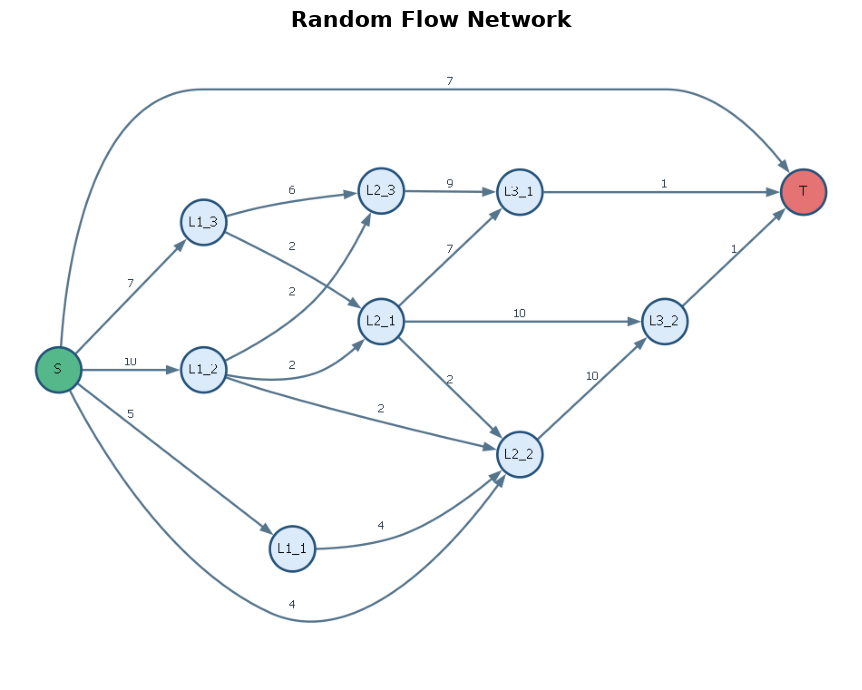

In [171]:
net = FlowNetwork(N=3, seed=400)

net.info()

net.visualize()

plt.show()

Maximum flow: 9

Edge flows:
S -> L1_3: 0/7
S -> L1_1: 0/5
S -> L1_2: 1/10
S -> L2_2: 1/4
S -> T: 7/7
L1_1 -> L2_2: 0/4
L1_2 -> L2_2: 0/2
L1_2 -> L2_1: 1/2
L1_2 -> L2_3: 0/2
L1_3 -> L2_3: 0/6
L1_3 -> L2_1: 0/2
L2_1 -> L3_2: 0/10
L2_1 -> L2_2: 0/2
L2_1 -> L3_1: 1/7
L2_2 -> L3_2: 1/10
L2_3 -> L3_1: 0/9
L3_1 -> T: 1/1
L3_2 -> T: 1/1


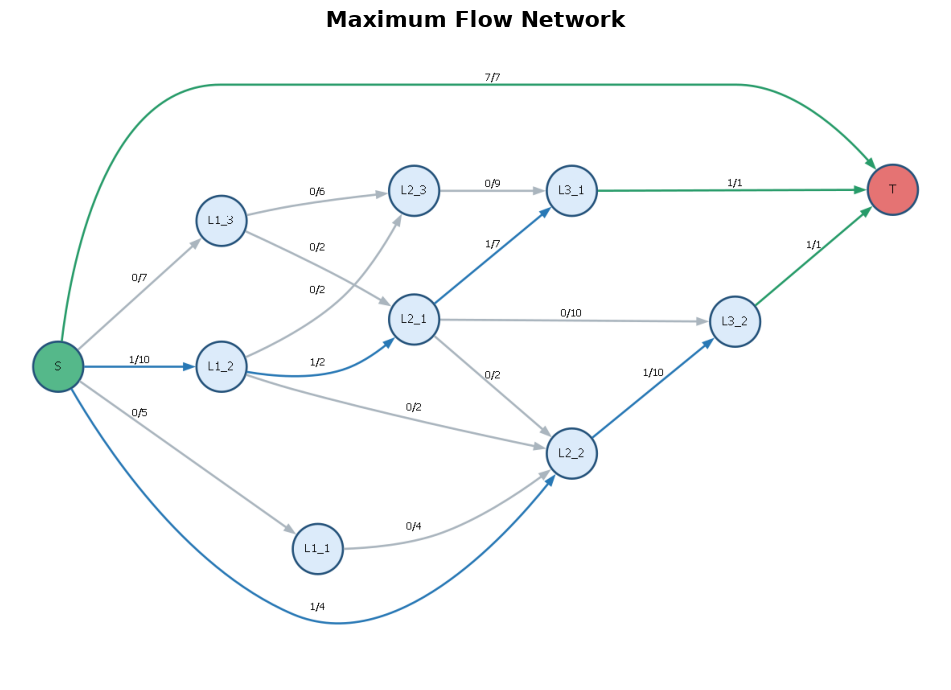

In [172]:
network = FlowNetwork(N=3, seed=400)

max_flow, flow = network.ford_fulkerson()

print("Maximum flow:", max_flow)

print("\nEdge flows:")

for (u, v), value in flow.items():
    print(
        f"{u} -> {v}: "
        f"{value}/{network.G[u][v]['capacity']}"
    )

network.visualize_flow(flow)
plt.show()